# ZniyerBuy AI Module - Prediction Validation Notebook

Validates the 6 live prediction modules under `app/services/` that power the
seller Analytics page's **"AI-Powered Predictions for Next Month"** section:

| # | Module | Prediction |
|---|---|---|
| 1 | `revenue_predictor.py` | Predicted Revenue (next month total) |
| 2 | `daily_revenue_avg.py` | Daily Revenue (average per day) |
| 3 | `user_traffic_predictor.py` | Expected Users |
| 4 | `top_category_classifier.py` | Next Month Top Category |
| 5 | `daily_revenue_forecast.py` | Daily Revenue Forecast (30-day series) |
| 6 | `category_sales_prediction.py` | Category Sales Prediction |

Unlike the old `notebooks/0X_*.ipynb` files (moved to `legacy-structure`Branch), this notebook
does **not** train anything and does **not** need the Kaggle Instacart dataset.
It imports the real service modules used by the FastAPI app and checks them
against synthetic order/product data shaped exactly like the real Supabase
`orders` / `products` tables - plus an optional final section to validate
against a real shop if you have Supabase credentials configured.

Run all cells top to bottom. Every section ends with an `assert` - if a cell
raises, something regressed.

## Setup - import the 6 predictor modules

In [1]:
import sys, os
sys.path.insert(0, '..')   # so `app.*` imports resolve from notebooks/

import random, json
from datetime import datetime, timedelta, timezone
import matplotlib.pyplot as plt
import numpy as np

from app.services import shared
from app.services.revenue_predictor import predict_next_month_revenue
from app.services.daily_revenue_avg import predict_average_daily_revenue
from app.services.daily_revenue_forecast import compute_daily_forecast, predict_daily_revenue_forecast
from app.services.user_traffic_predictor import predict_expected_users
from app.services.top_category_classifier import predict_top_category
from app.services.category_sales_prediction import predict_category_sales, predict_category_sales_response
from app.services.predictions_aggregator import build_shop_predictions

print("All 6 predictor modules + shared + aggregator imported successfully.")


All 6 predictor modules + shared + aggregator imported successfully.


## Sample data

Shaped exactly like what `app/database.py` returns from Supabase:
`orders` -> `id, total_amount, status, customer_phone, customer_name, created_at`
`products` -> `id, category, views, favorites_count, average_rating, recommendation_score`

In [2]:
random.seed(11)

def make_sample_orders(n_days=60, orders_per_day_range=(0, 5), base_price=(500, 5000), cancel_rate=0.2):
    base_date = datetime.now(timezone.utc) - timedelta(days=n_days)
    orders = []
    for i in range(n_days):
        day = base_date + timedelta(days=i)
        n = random.randint(*orders_per_day_range)
        for j in range(n):
            status = 'cancelled' if random.random() < cancel_rate else 'delivered'
            orders.append({
                'id': f'order-{i}-{j}',
                'total_amount': round(random.uniform(*base_price) * (1 + i / n_days), 2),  # mild upward trend
                'status': status,
                'customer_phone': f'07{random.randint(10_000_000, 99_999_999)}',
                'customer_name': f'Customer {random.randint(1, 40)}',
                'created_at': day.isoformat(),
            })
    return orders

sample_orders = make_sample_orders()

sample_products = [
    {'category': 'Electronics', 'views': 540, 'favorites_count': 42, 'average_rating': 4.6, 'recommendation_score': 88},
    {'category': 'Electronics', 'views': 310, 'favorites_count': 18, 'average_rating': 4.1, 'recommendation_score': 55},
    {'category': 'Fashion',     'views': 210, 'favorites_count': 15, 'average_rating': 4.0, 'recommendation_score': 34},
    {'category': 'Fashion',     'views': 95,  'favorites_count': 6,  'average_rating': 3.8, 'recommendation_score': 20},
    {'category': 'Food',        'views': 860, 'favorites_count': 95, 'average_rating': 4.8, 'recommendation_score': 130},
    {'category': 'Home',        'views': 60,  'favorites_count': 4,  'average_rating': 3.4, 'recommendation_score': 9},
]

print(f"Generated {len(sample_orders)} sample orders across 60 simulated days, "
      f"{len(sample_products)} sample products across {len(set(p['category'] for p in sample_products))} categories.")


Generated 143 sample orders across 60 simulated days, 6 sample products across 4 categories.


## 1. `revenue_predictor.py` - Predicted Revenue

In [3]:
r1 = predict_next_month_revenue(sample_orders)
print(f"status               = {r1['status']}")
print(f"predicted_revenue    = Rs. {r1['predicted_revenue']:,.2f}")
print(f"confidence           = {r1['confidence']}")

assert r1['status'] == 'ok'
assert r1['predicted_revenue'] > 0
print("PASS")


status               = ok
predicted_revenue    = Rs. 374,853.62
confidence           = high
PASS


## 2. `daily_revenue_avg.py` - Daily Revenue (average per day)

Must always equal `predicted_revenue / 30` - both files share the same underlying 30-day forecast from `daily_revenue_forecast.py`, so they can never disagree.

In [4]:
r2 = predict_average_daily_revenue(sample_orders)
print(f"status                     = {r2['status']}")
print(f"predicted_daily_revenue    = Rs. {r2['predicted_daily_revenue']:,.2f}")

assert r2['status'] == 'ok'
assert abs(r1['predicted_revenue'] - r2['predicted_daily_revenue'] * 30) < 0.5
print("PASS  (matches predicted_revenue / 30, no drift between the two files)")


status                     = ok
predicted_daily_revenue    = Rs. 12,495.12
PASS  (matches predicted_revenue / 30, no drift between the two files)


## 3. `user_traffic_predictor.py` - Expected Users

In [5]:
r3 = predict_expected_users(sample_orders)
print(f"status            = {r3['status']}")
print(f"expected_users    = {r3['expected_users']}")

assert r3['status'] == 'ok'
assert r3['expected_users'] >= 0
print("PASS")


status            = ok
expected_users    = 83
PASS


## 4. `top_category_classifier.py` - Next Month Top Category

In [6]:
r4 = predict_top_category(sample_products)
print(f"status                          = {r4['status']}")
print(f"top_category                    = {r4['top_category']}")
print(f"top_category_predicted_sales    = {r4['top_category_predicted_sales']}")

assert r4['status'] == 'ok'
print("PASS")


status                          = ok
top_category                    = Electronics
top_category_predicted_sales    = 2
PASS


## 5. `daily_revenue_forecast.py` - Daily Revenue Forecast (30-day series)

In [7]:
r5 = predict_daily_revenue_forecast(sample_orders)
print(f"status              = {r5['status']}")
print(f"forecast length     = {len(r5['daily_revenue_forecast'])} days")
print(f"confidence          = {r5['confidence']}")
print(f"first day forecast  = Rs. {r5['daily_revenue_forecast'][0]['revenue']:,.2f}")
print(f"last day forecast   = Rs. {r5['daily_revenue_forecast'][-1]['revenue']:,.2f}")

assert r5['status'] == 'ok'
assert len(r5['daily_revenue_forecast']) == 30
print("PASS")


status              = ok
forecast length     = 30 days
confidence          = high
first day forecast  = Rs. 10,837.45
last day forecast   = Rs. 14,152.79
PASS


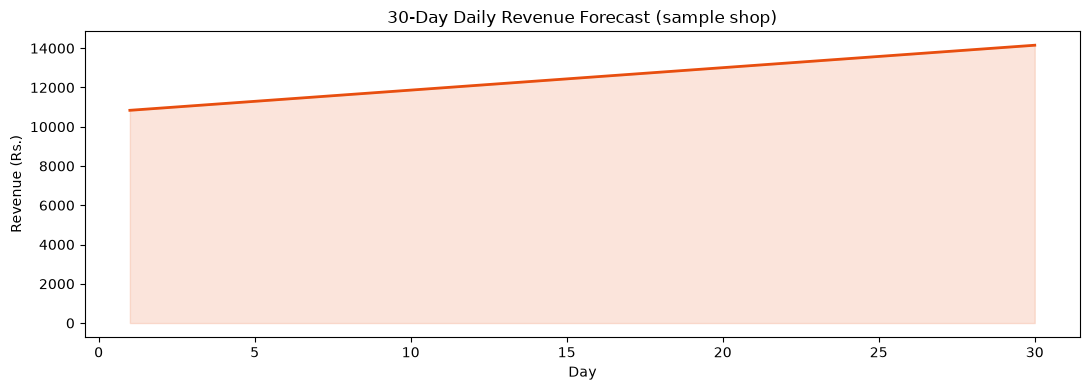

In [8]:
xs = [f['day'] for f in r5['daily_revenue_forecast']]
ys = [f['revenue'] for f in r5['daily_revenue_forecast']]

plt.figure(figsize=(11, 4))
plt.plot(range(1, 31), ys, color='#E84E0F', linewidth=2)
plt.fill_between(range(1, 31), ys, alpha=0.15, color='#E84E0F')
plt.title('30-Day Daily Revenue Forecast (sample shop)')
plt.xlabel('Day'); plt.ylabel('Revenue (Rs.)')
plt.tight_layout()
plt.show()


## 6. `category_sales_prediction.py` - Category Sales Prediction

`top_category_classifier.py` (module 4) must always return the #1 row from this list - checked below.

In [9]:
r6 = predict_category_sales_response(sample_products)
print(f"status             = {r6['status']}")
print(f"category_basis     = {r6['category_basis']}")
for c in r6['category_sales_prediction']:
    print(f"  {c['name']:<12} current={c['current']:<3} predicted={c['predicted']}")

assert r6['status'] == 'ok'
assert r6['category_sales_prediction'][0]['name'] == r4['top_category']
print("PASS  (top row matches top_category_classifier.py's answer)")


status             = ok
category_basis     = catalog_engagement_proxy
  Electronics  current=2   predicted=2
  Fashion      current=2   predicted=2
  Food         current=1   predicted=2
  Home         current=1   predicted=1
PASS  (top row matches top_category_classifier.py's answer)


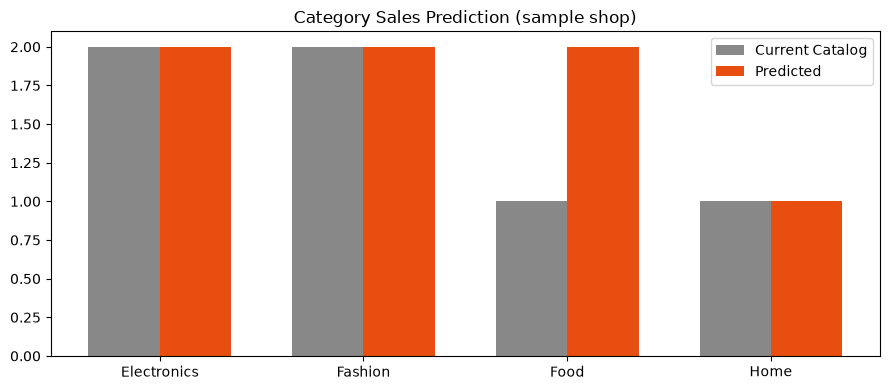

In [10]:
names = [c['name'] for c in r6['category_sales_prediction']]
current = [c['current'] for c in r6['category_sales_prediction']]
predicted = [c['predicted'] for c in r6['category_sales_prediction']]

x = np.arange(len(names)); width = 0.35
plt.figure(figsize=(9, 4))
plt.bar(x - width/2, current, width, label='Current Catalog', color='#888888')
plt.bar(x + width/2, predicted, width, label='Predicted', color='#E84E0F')
plt.xticks(x, names)
plt.title('Category Sales Prediction (sample shop)')
plt.legend()
plt.tight_layout()
plt.show()


## 7. `predictions_aggregator.py` - full response (what the API actually returns)

This is exactly the JSON `GET /predictions/shop/{shop_id}` returns, and exactly
what the backend forwards to the Analytics page.

In [11]:
full = build_shop_predictions(sample_orders, sample_products)
print(json.dumps({k: v for k, v in full.items() if k != 'daily_revenue_forecast'}, indent=2))

assert full['status'] == 'ok'
assert full['predicted_revenue'] == r1['predicted_revenue']
assert full['predicted_daily_revenue'] == r2['predicted_daily_revenue']
assert full['expected_users'] == r3['expected_users']
assert full['top_category'] == r4['top_category']
print("PASS  (aggregator output matches each individual module exactly)")


{
  "status": "ok",
  "predicted_revenue": 374853.62,
  "predicted_daily_revenue": 12495.12,
  "expected_users": 83,
  "top_category": "Electronics",
  "top_category_predicted_sales": 2,
  "category_sales_prediction": [
    {
      "name": "Electronics",
      "current": 2,
      "predicted": 2
    },
    {
      "name": "Fashion",
      "current": 2,
      "predicted": 2
    },
    {
      "name": "Food",
      "current": 1,
      "predicted": 2
    },
    {
      "name": "Home",
      "current": 1,
      "predicted": 1
    }
  ],
  "meta": {
    "total_orders": 111,
    "history_days": 60,
    "confidence": "high",
    "category_basis": "catalog_engagement_proxy"
  }
}
PASS  (aggregator output matches each individual module exactly)


## 8. Edge cases - no crashes, no fabricated numbers

In [12]:
no_data = build_shop_predictions(sample_orders[:2], sample_products)
assert no_data['status'] == 'no_data'
assert no_data['predicted_revenue'] is None
print("Sparse shop (<3 orders)  -> status='no_data', no fabricated numbers   PASS")

no_products = build_shop_predictions(sample_orders, [])
assert no_products['top_category'] is None
assert no_products['category_sales_prediction'] == []
print("Shop with no products    -> top_category=None, revenue still computed  PASS")

no_orders = build_shop_predictions([], [])
assert no_orders['status'] == 'no_data'
print("Brand-new shop, zero orders -> status='no_data'                        PASS")


Sparse shop (<3 orders)  -> status='no_data', no fabricated numbers   PASS
Shop with no products    -> top_category=None, revenue still computed  PASS
Brand-new shop, zero orders -> status='no_data'                        PASS


## 9. Optional - validate against a real shop

Requires `SUPABASE_URL` / `SUPABASE_KEY` in `../.env` (see `.env.example`) and a
real `shop_id` with at least a few orders. Safe to skip - everything above
already validates the logic on its own.

In [13]:
REAL_SHOP_ID = None  # paste a real shop UUID here to test against live data

if REAL_SHOP_ID:
    from app.database import get_orders_by_shop, get_products_by_shop
    real_orders = get_orders_by_shop(REAL_SHOP_ID)
    real_products = get_products_by_shop(REAL_SHOP_ID)
    real_result = build_shop_predictions(real_orders, real_products)
    print(json.dumps(real_result, indent=2))
else:
    print("Skipped — set REAL_SHOP_ID above to validate against a live shop.")


Skipped — set REAL_SHOP_ID above to validate against a live shop.


## Summary

In [15]:
print("ALL 6 PREDICTION MODULES VALIDATED SUCCESSFULLY")
for name in [
    "1. revenue_predictor.py            -> Predicted Revenue",
    "2. daily_revenue_avg.py            -> Daily Revenue (avg/day)",
    "3. user_traffic_predictor.py       -> Expected Users",
    "4. top_category_classifier.py      -> Next Month Top Category",
    "5. daily_revenue_forecast.py       -> 30-Day Daily Revenue Forecast",
    "6. category_sales_prediction.py    -> Category Sales Prediction",
]:
    print("  PASS  " + name)


ALL 6 PREDICTION MODULES VALIDATED SUCCESSFULLY
  PASS  1. revenue_predictor.py            -> Predicted Revenue
  PASS  2. daily_revenue_avg.py            -> Daily Revenue (avg/day)
  PASS  3. user_traffic_predictor.py       -> Expected Users
  PASS  4. top_category_classifier.py      -> Next Month Top Category
  PASS  5. daily_revenue_forecast.py       -> 30-Day Daily Revenue Forecast
  PASS  6. category_sales_prediction.py    -> Category Sales Prediction
